# SINT-666 | Clase 1 — Fundamentos de Redes Neuronales con Python
**Universidad CENFOTEC · Docente: Jorge Ortega Badilla**

Objetivos: explicar una neurona, experimentar con activaciones, explorar datos, construir y evaluar una red básica. **Datos completamente sintéticos**: no representan procesos ni decisiones reales.


## 1. Activación inicial: ¿reglas o aprendizaje?
**Pregunta:** ¿una temperatura alta por sí sola determina un defecto? ¿Qué pasa si interactúa con la vibración?

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

np.random.seed(42)
tf.keras.utils.set_random_seed(42)
print("TensorFlow:",tf.__version__)

TensorFlow: 2.21.0


## 2. Una neurona manual con NumPy
Calcule $z=x\cdot w+b$ y $a=\sigma(z)$. Antes de ejecutar, prediga el resultado.

In [ ]:
x=np.array([0.8,0.4]); w=np.array([0.6,-0.3]); b=0.1
z=np.dot(x,w)+b
a=1/(1+np.exp(-z))
print(f"z={z:.3f}; activación sigmoid={a:.3f}")
assert np.isclose(z,0.46)

z=0.460; activación sigmoid=0.613


**Experimento:** cambie el primer peso a -0.6. ¿Por qué cambia la salida? Restaure el valor antes de seguir.

## 3. Funciones de activación
La no linealidad permite representar relaciones más complejas que una transformación afín.

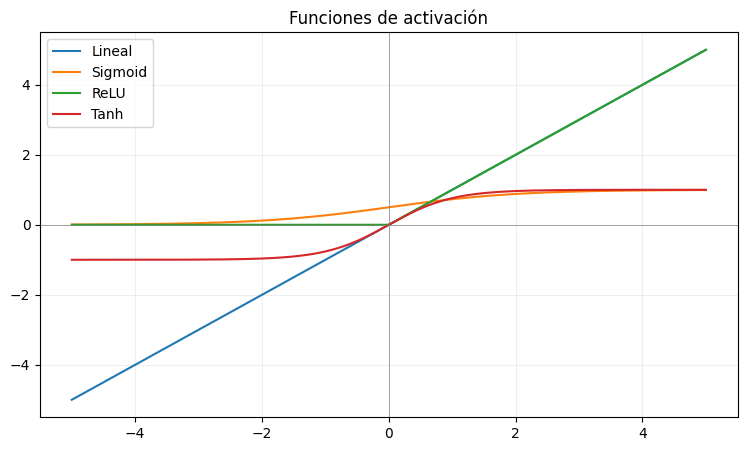

In [ ]:
z=np.linspace(-5,5,300)
funciones={"Lineal":z,"Sigmoid":1/(1+np.exp(-z)),"ReLU":np.maximum(0,z),"Tanh":np.tanh(z)}
plt.figure(figsize=(9,5))
for nombre,resultado in funciones.items(): plt.plot(z,resultado,label=nombre)
plt.axhline(0,color="gray",lw=.5);plt.axvline(0,color="gray",lw=.5)
plt.legend();plt.grid(alpha=.2);plt.title("Funciones de activación");plt.show()

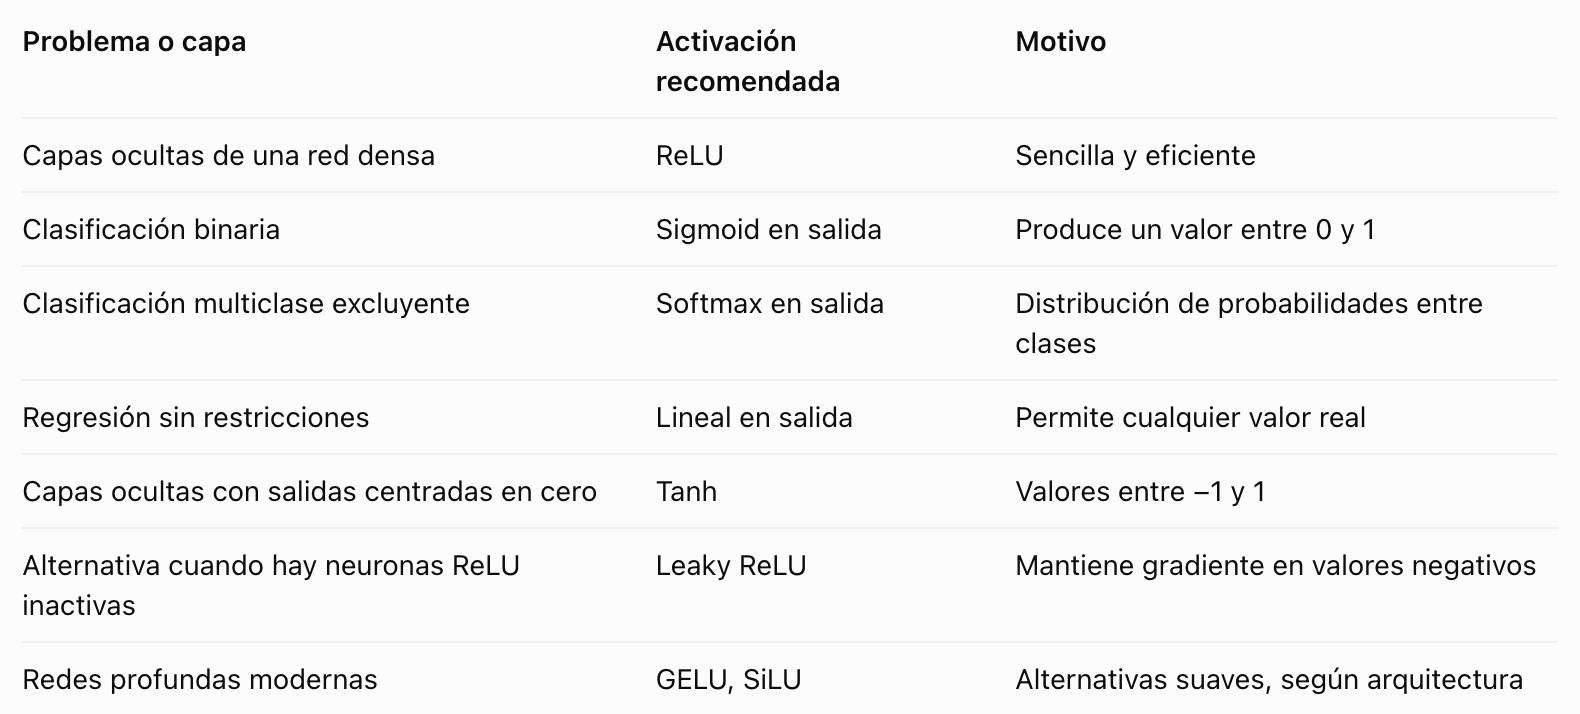

## 4. Caso de estudio: calidad industrial
**Variable objetivo:** `defectuosa` (1=defectuosa, 0=no defectuosa). Cuatro sensores de entrada. Datos simulados con ruido e interacciones.

In [ ]:
# from google.colab import files
# uploaded = files.upload()
# archivo = next(iter(uploaded))
# df = pd.read_csv(archivo)
# print('Archivo cargado:', archivo)
# display(df.head())


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Cursos/SINT-666 Fundamento de redes neuronales/Clase 1/datos_industriales_profesor.csv')
display(df.head())

,temperatura_c,presion_bar,velocidad_unidades_min,vibracion_mm_s,defectuosa
0,185.89,69.52,29.22,0.372,0
1,191.95,85.00,45.22,0.581,0
2,181.74,77.26,41.11,0.223,0
3,145.19,59.27,30.64,0.595,0
4,222.76,57.36,52.17,0.269,0


In [ ]:
print("Dimensiones:", df.shape)

Dimensiones: (900, 5)


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
temperatura_c,900.0,184.964044,17.083411,131.98,172.8600,185.045,196.09250,238.420
presion_bar,900.0,71.379578,12.992304,35.00,63.0125,71.170,79.70000,110.000
velocidad_unidades_min,900.0,44.530789,9.942086,16.95,37.4450,44.500,51.28000,75.000
vibracion_mm_s,900.0,0.382304,0.160418,0.03,0.2750,0.392,0.48725,0.812
defectuosa,900.0,0.154444,0.361575,0.00,0.0000,0.000,0.00000,1.000


In [ ]:
print("Proporciones de las clases")
display(df.defectuosa.value_counts(normalize=True))

Proporciones de las clases


,proportion
defectuosa,
0,0.845556
1,0.154444


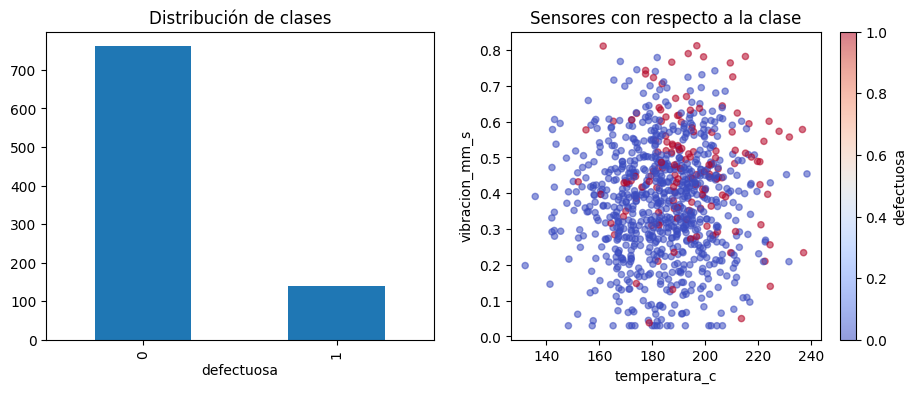

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df.defectuosa.value_counts().sort_index().plot(kind="bar", ax=ax[0], title="Distribución de clases")
df.plot.scatter(x='temperatura_c', y="vibracion_mm_s", c="defectuosa", cmap="coolwarm", alpha=0.55, ax=ax[1], title="Sensores con respecto a la clase")
plt.show()

## 5. Separar y normalizar
Separamos primero para evitar fuga de información. El escalador se ajusta **solo con entrenamiento**. Conservamos test para la evaluación final.

In [ ]:
X = df.drop(columns="defectuosa")
y = df.defectuosa
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Dimensiones:", X_train.shape, X_test.shape, y_train.shape, y_test.shape)

Dimensiones: (720, 4) (180, 4) (720,) (180,)


In [ ]:
escalador= StandardScaler()
escalador.fit(X_train)
X_train_s=escalador.transform(X_train)
X_test_s=escalador.transform(X_test)

## 6. Primera red neuronal
Arquitectura 4 → 6 (ReLU) → 1 (Sigmoid). **37 parámetros**. Compilar no entrena: solo configura cómo entrenar.

In [ ]:
modelo = keras.Sequential([keras.Input(shape=(4,)), keras.layers.Dense(6, activation="relu"), keras.layers.Dense(1, activation="sigmoid")])
modelo.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6)              │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             7 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 37 (148.00 B)

 Trainable params: 37 (148.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
assert modelo.count_params() == 37

## 7. Entrenamiento y curvas
`epochs`: pasadas completas; `batch_size`: observaciones por actualización; `validation_split`: parte del entrenamiento usada para validación.

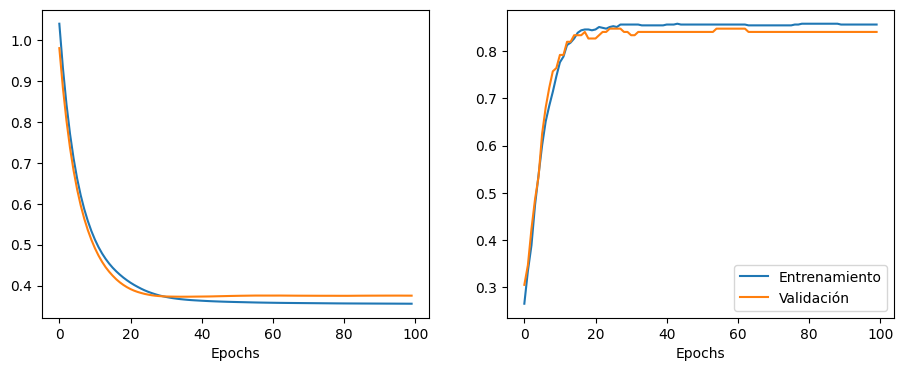

In [ ]:
print("Inicio entrenamiento")
hist = modelo.fit(X_train_s, y_train, epochs=100, batch_size=16, validation_split=0.2, verbose=0)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for j, metrica in enumerate(["loss", "accuracy"]):
  ax[j].plot(hist.history[metrica], label="Entrenamiento")
  ax[j].plot(hist.history[f"val_{metrica}"], label="Validación")
  ax[j].set_xlabel("Epochs")
plt.legend()
plt.show()




## 8. Evaluación e interpretación
Una exactitud alta no basta: observar matriz de confusión y distribución de clases. Las probabilidades pueden estar mal calibradas.

Loss test: 0.380; Accuracy test: 0.833
              precision    recall  f1-score   support

           0       0.85      0.97      0.91       149
           1       0.56      0.16      0.25        31

    accuracy                           0.83       180
   macro avg       0.70      0.57      0.58       180
weighted avg       0.80      0.83      0.79       180



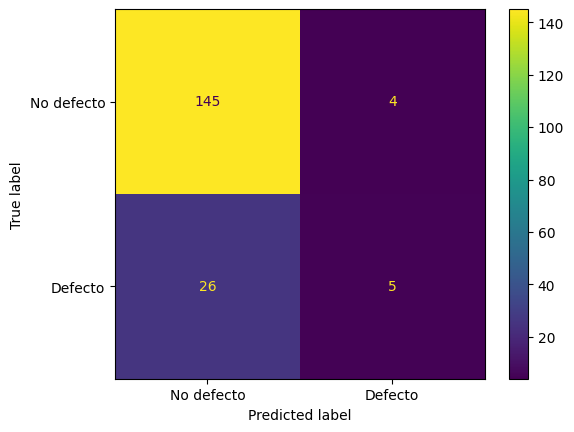

Ejemplo de probabilidades: [0.091 0.047 0.012 0.287 0.273 0.546 0.503 0.273]


In [ ]:
perdida,exactitud=modelo.evaluate(X_test_s,y_test,verbose=0)
probs=modelo.predict(X_test_s,verbose=0).ravel()
preds=(probs>=.5).astype(int)
print(f"Loss test: {perdida:.3f}; Accuracy test: {exactitud:.3f}")
print(classification_report(y_test,preds,zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test,preds,display_labels=["No defecto","Defecto"]);plt.show()
print("Ejemplo de probabilidades:",np.round(probs[:8],3))

## 9. Preguntas de cierre y demostración adicional
1. ¿Qué hace el sesgo? 2. ¿Qué pasaría sin ReLU? 3. ¿Por qué se normaliza? 4. ¿Cuál es la diferencia entre pérdida y exactitud? 5. ¿Qué riesgos tiene una clasificación incorrecta?

**Reto opcional:** cambie 6 neuronas ocultas por 12 y compare el número de parámetros y resultados. Mantenga el conjunto de prueba intacto.

**Limitación:** los datos fueron generados con reglas sintéticas; los resultados no prueban desempeño industrial real.